# Used Car Price Predictor

**Goal:** build a model that predicts the resale price of a used car (in lakhs) from its details.

**Data:** `cars_clean.csv`, the cleaned data from Project 1.

**Steps:** 1. Set up → 2. Baseline → 3. Train models → 4. Compare → 5. What matters most → 6. Conclusions

## 1. The idea in plain words

A machine learning model learns patterns from examples. We show it thousands of cars *with* their prices, and it learns how details like year, brand and engine size relate to price. Then we give it a car it has never seen and ask it to guess the price.

Two words you'll see everywhere:
- **Features** are the inputs, the details we know about a car (year, brand, kilometers…). Called `X`.
- **Target** is what we want to predict, the price. Called `y`.

**Train/test split.** Imagine a student who sees the exam questions in advance. A perfect score would prove nothing. So we hide 20% of the cars (the **test set**) and train the model on the other 80% (the **training set**). We then judge the model on the hidden cars, which is a fair exam.

## 2. Load the data and choose the features

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("../data/cars_clean.csv")
df.shape

(5806, 13)

We split the features into two kinds, because models handle them differently:
- **Numeric** features are already numbers.
- **Categorical** features are labels like `Diesel` or `BMW`. Models need numbers, so later we convert each label into 0/1 columns (this is called *one-hot encoding*).

We leave out `Name`. It is too specific (thousands of unique values) and `Brand` already captures the useful part. We also leave out `Price`, because that's the answer we're predicting.

In [14]:
numeric_features = ["Year", "Kilometers_Driven", "Mileage", "Engine", "Power", "Seats"]
categorical_features = ["Brand", "Fuel_Type", "Transmission", "Owner_Type", "Location"]

X = df[numeric_features + categorical_features]   # features (inputs)
y = df["Price"]                                    # target (what we predict)

X.head()

,Year,Kilometers_Driven,Mileage,Engine,Power,Seats,Brand,Fuel_Type,Transmission,Owner_Type,Location
0,2015,41000,19.67,1582.0,126.20,5.0,Hyundai,Diesel,Manual,First,Pune
1,2011,46000,13.00,1199.0,88.70,5.0,Honda,Petrol,Manual,First,Chennai
2,2012,87000,20.77,1248.0,88.76,7.0,Maruti,Diesel,Manual,First,Chennai
3,2013,40670,15.20,1968.0,140.80,5.0,Audi,Diesel,Automatic,Second,Coimbatore
4,2013,86999,23.08,1461.0,63.10,5.0,Nissan,Diesel,Manual,First,Jaipur


### Split into training and test sets

`test_size=0.2` hides 20% of the cars. `random_state=42` fixes the shuffle, so you get the same split every time (any number works, it just makes results repeatable).

In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training cars:", len(X_train))
print("Test cars:    ", len(X_test))

Training cars: 4644
Test cars:     1162


## 3. Baseline: how good is a lazy guess?

Before building a clever model, we need something to beat. The laziest model ignores every detail and always predicts the same price for every car, either the average or the median of the training prices.

We measure the results with two scores:
- **MAE (Mean Absolute Error):** the average size of the mistake, in lakhs. *Lower is better.* An MAE of 2 means predictions are off by 2 lakhs on average.
- **R² (R-squared):** how much of the price differences the model explains. *1 is perfect, 0 means no better than always guessing the average, and below 0 is worse than that.*

In [16]:
for strategy in ["mean", "median"]:
    baseline = DummyRegressor(strategy=strategy).fit(X_train, y_train)
    predictions = baseline.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print(f"Always guess the {strategy:6}: MAE = {mae:.2f} lakhs, R² = {r2:.3f}")

Always guess the mean  : MAE = 6.92 lakhs, R² = -0.002
Always guess the median: MAE = 5.70 lakhs, R² = -0.111


**What we learn:** a model that ignores every detail is off by about **5.7 to 6.9 lakhs** on average, and its R² is about 0 or below. This is the bar to beat. Any real model must have a clearly lower MAE and an R² well above 0.

Next, we train real models and see how much better they do.

## 4. Prepare the features

Models only understand numbers, but `Brand` and `Fuel_Type` are words. The fix is **one-hot encoding**: each label becomes its own column that is 1 if the car has that label and 0 if not. A tiny example:

In [17]:
pd.get_dummies(X_train["Fuel_Type"]).head()

,Diesel,Petrol
4900,True,False
3182,False,True
4763,False,True
3893,False,True
4695,True,False


Each car has a 1 in exactly one column. We do this for all five label columns. Numeric columns are passed through unchanged.

A **Pipeline** chains the preparation and the model into one object, so the same preparation is applied automatically to the training cars and the test cars. `handle_unknown="ignore"` stops it crashing if a test car has a label it never saw in training.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

prepare = ColumnTransformer([
    ("numbers", "passthrough", numeric_features),
    ("labels", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

# See how many columns the models will actually receive
prepare.fit_transform(X_train).shape

(4644, 53)

Our 11 features became **53 columns** (6 numeric + 47 one-hot columns for brands, fuel types, cities and so on).

## 5. A helper to score any model

We'll score several models, so we write the scoring steps once as a **function**. It trains the model, predicts for both the training cars and the test cars, and prints the scores for each. Comparing the two is important, as you'll see.

In [19]:
results = []   # we collect each model's scores here

def score_model(name, model):
    pipeline = Pipeline([("prepare", prepare), ("model", model)])
    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    row = {
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Test R²": r2_score(y_test, test_pred),
    }
    results.append(row)
    print(f"{name}: Train MAE = {row['Train MAE']:.2f}, Test MAE = {row['Test MAE']:.2f}, Test R² = {row['Test R²']:.3f}")
    return pipeline, test_pred

## 6. Model 1: Linear regression

It learns one number for each column, like *"each year newer adds this much"*, and adds them up. It's simple and fast. This is the same model you used on 5 cars in the practice notebook.

In [20]:
linear_model, linear_pred = score_model("Linear regression", LinearRegression())

Linear regression: Train MAE = 3.50, Test MAE = 3.41, Test R² = 0.722


**What we learn:** the test MAE is about **3.4 lakhs**, much better than the baseline's 5.7, and R² is about 0.72. So the car details really do help.

But linear regression can only add things up in a straight line, and prices don't work that way. Let's look for a symptom:

In [21]:
print("Cars with a negative predicted price:", (linear_pred < 0).sum(), "out of", len(linear_pred))
print("Lowest predicted price:", round(linear_pred.min(), 1), "lakhs")

Cars with a negative predicted price: 128 out of 1162
Lowest predicted price: -12.7 lakhs


A car can't cost less than nothing. This model predicts negative prices for old, cheap cars, because a straight line keeps going down. That's a sign we need a model that can handle curves.

## 7. Model 2: Random forest

A **decision tree** predicts by asking yes/no questions: *Is it newer than 2016? Is the power above 150 bhp? Is it a luxury brand?* Each path ends at a price. A **random forest** builds many trees (here 200) on slightly different samples of the cars and averages their answers, which is more reliable than any single tree.

Because trees ask questions, they can handle cases like *"a BMW loses value differently than a Maruti"*. `random_state=42` makes the result repeatable, and `n_jobs=-1` uses all your computer's cores to go faster.

In [22]:
forest_model, forest_pred = score_model(
    "Random forest",
    RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
)

Random forest: Train MAE = 0.53, Test MAE = 1.48, Test R² = 0.855


**What we learn:** the test MAE drops to about **1.5 lakhs** and R² rises to about 0.86. That's a big improvement over the linear model.

**Look at the gap, though.** On the training cars the forest is off by only about 0.5 lakhs, but on the hidden test cars it is off by about 1.5. It does much better on cars it has seen than on new ones. This is called **overfitting**: the model partly *memorises* the training cars instead of learning only the general pattern.

This is exactly why we keep a hidden test set. If we had only looked at the training score, we would have thought the model was almost perfect. The test score is the honest one.

## 8. Compare all three

We add the baseline for reference, then put everything in one table. We sort by **Test MAE**, since the test cars give the honest score.

In [23]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
results.append({
    "Model": "Baseline (always the median)",
    "Train MAE": mean_absolute_error(y_train, baseline.predict(X_train)),
    "Test MAE": mean_absolute_error(y_test, baseline_pred),
    "Test R²": r2_score(y_test, baseline_pred),
})

comparison = pd.DataFrame(results).sort_values("Test MAE").round(2).reset_index(drop=True)
comparison

,Model,Train MAE,Test MAE,Test R²
0,Random forest,0.53,1.48,0.86
1,Linear regression,3.50,3.41,0.72
2,Baseline (always the median),6.20,5.70,-0.11


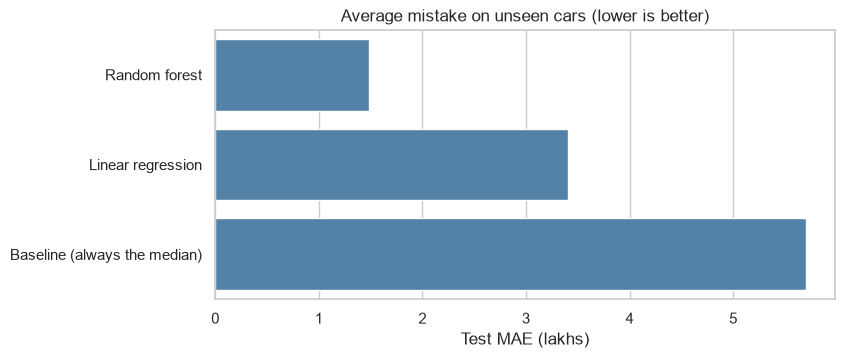

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 3.5))
sns.barplot(data=comparison, x="Test MAE", y="Model", color="steelblue")
plt.title("Average mistake on unseen cars (lower is better)")
plt.xlabel("Test MAE (lakhs)")
plt.ylabel("")
plt.show()

**Summary:**

| Model | Average mistake | What it tells us |
|---|---|---|
| Baseline (lazy guess) | about 5.7 lakhs | the bar to beat |
| Linear regression | about 3.4 lakhs | the details help, but it predicts impossible negative prices |
| Random forest | about 1.5 lakhs | best, about 4 times better than the baseline |

The random forest is our best model so far.

## 9. Which details matter most?

The random forest can tell us how much it relied on each detail. This is called **feature importance**. The importances add up to 100%, so each number is that detail's share of the decision.

One technical point: after one-hot encoding, `Brand` became many columns (Brand_BMW, Brand_Audi…). We add those back together so that each *original* detail gets one number.

In [25]:
names = forest_model.named_steps["prepare"].get_feature_names_out()
importances = forest_model.named_steps["model"].feature_importances_

grouped = {}
for name, value in zip(names, importances):
    feature = name.split("__", 1)[1]            # remove the "numbers__" or "labels__" prefix
    for label_column in categorical_features:
        if feature.startswith(label_column + "_"):
            feature = label_column               # Brand_BMW, Brand_Audi ... all become Brand
    grouped[feature] = grouped.get(feature, 0) + value

importance = (pd.Series(grouped) * 100).sort_values(ascending=False)
importance.round(1)

Power                66.3
Year                 16.4
Brand                 4.5
Kilometers_Driven     4.1
Engine                3.5
Location              2.1
Mileage               1.7
Seats                 0.6
Transmission          0.5
Fuel_Type             0.2
Owner_Type            0.1
dtype: float64

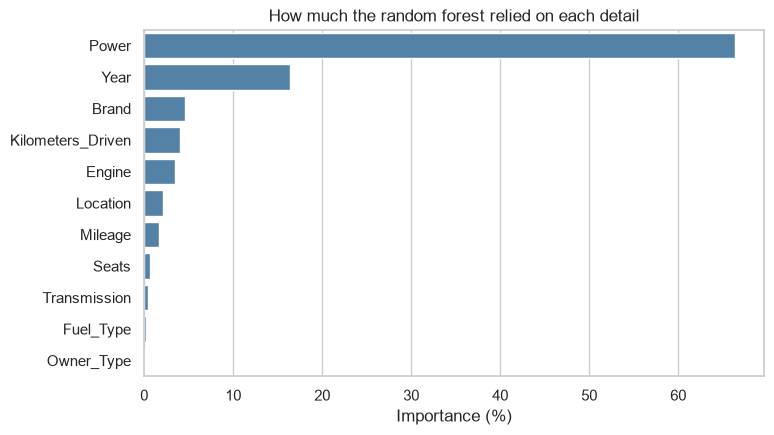

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4.5))
sns.barplot(x=importance.values, y=importance.index, color="steelblue")
plt.title("How much the random forest relied on each detail")
plt.xlabel("Importance (%)")
plt.ylabel("")
plt.show()

**What we learn:**
- **Power (66%)** and **Year (16%)** make up over 80% of the model's decisions. Powerful, newer cars cost more.
- **Brand is only 4.5%**, which looks surprising after Project 1 showed brand strongly affects price. But brand and power are tangled together: luxury brands have powerful engines, so once the model knows the power, it already knows a lot about the brand. Importance shows what the model *used*, not what matters in the real world on its own.
- **Kilometers (4%)** matters little, which agrees with Project 1, where the link was weak (correlation -0.16).
- **Fuel type (0.2%)** is almost unused. This agrees with our warning in Project 1 that diesel looked pricier mainly because diesel cars have bigger engines.

**Takeaway:** the model's choices match what we found by exploring in Project 1.

## 10. Try it on real cars

Numbers like "1.5 lakhs average error" are hard to picture. Here are 6 random cars from the hidden test set, with the model's guess next to the real price.

In [27]:
sample = X_test.sample(6, random_state=1)

examples = sample[["Brand", "Year", "Kilometers_Driven", "Power"]].copy()
examples["Real price"] = y_test.loc[sample.index]
examples["Predicted"] = forest_model.predict(sample).round(2)
examples["Mistake"] = (examples["Predicted"] - examples["Real price"]).abs().round(2)
examples

,Brand,Year,Kilometers_Driven,Power,Real price,Predicted,Mistake
4013,Audi,2009,88000,140.00,7.98,11.15,3.17
2225,Land Rover,2010,45000,241.40,40.00,28.15,11.85
3450,Hyundai,2013,70000,55.20,1.80,2.23,0.43
4162,Maruti,2008,85000,103.20,2.50,2.48,0.02
296,Volkswagen,2011,108626,103.60,3.65,4.38,0.73
4145,Hyundai,2008,82203,68.05,1.80,1.88,0.08


**What we learn:**
- For the cheaper cars (Hyundai, Maruti, Volkswagen) the guesses are very close, all within about 0.7 lakhs and often much less.
- The model is weaker on expensive cars. The Land Rover (real 40 lakhs) is guessed at about 28, and the Audi is overestimated by about 3 lakhs. There are far fewer expensive cars to learn from, so the model has seen fewer examples of them.

This is a useful limitation to mention in the conclusions.

## 11. Save the trained model

Training takes a few seconds now, but we don't want to retrain every time we use the model. We **save** the trained model to a file. In Project 3, the dashboard will load this file and make predictions instantly. `joblib` is the standard tool for this.

In [28]:
import joblib
from pathlib import Path

Path("../models").mkdir(exist_ok=True)       # make a models/ folder if it doesn't exist
joblib.dump(forest_model, "../models/price_model.joblib")

size_mb = Path("../models/price_model.joblib").stat().st_size / 1_000_000
print(f"Saved. File size: {size_mb:.1f} MB")

Saved. File size: 81.2 MB


## 12. Conclusions

I trained models to predict the resale price of a used car in India from its details, using 5,806 cleaned listings (4,644 for training and 1,162 hidden for testing).

**Key findings**

1. **The random forest was the best model.** On cars it had never seen, its predictions were off by **1.48 lakhs** on average (R² = 0.86). Always guessing the median price is off by 5.70 lakhs, so the forest is about four times more accurate.
2. **Linear regression was in between** (3.41 lakhs, R² = 0.72) and predicted impossible negative prices for 128 of the 1,162 test cars, because a straight line cannot capture how prices behave.
3. **The forest overfits a little.** It is off by only 0.53 lakhs on training cars but 1.48 on test cars, which is why scoring on hidden cars matters.
4. **Power (66%) and Year (16%) drive the predictions**, over 80% together. This agrees with the exploration in Project 1. Brand scores only 4.5% because it overlaps with power (luxury brands have powerful engines). Kilometers and fuel type matter very little.
5. **Accuracy is best on cheaper cars.** Guesses for cheap cars were typically within 0.7 lakhs, but a 40-lakh Land Rover was guessed at about 28, since there are far fewer expensive cars to learn from.

**Limitations**

- The data comes from one source (Cars24) and covers cars up to 2019, so predictions may not match today's market.
- I used a single train/test split and did not tune the model's settings, so the score could probably be improved a little.
- Expensive and rare cars have little data, so predictions for them are less reliable.
- Feature importance shows what the model *used*, not what *causes* a price. Power, year and brand are tangled together.

**Next steps**

- Project 3: build a dashboard that loads the saved model and predicts a price from details the user enters.
- Try tuning the random forest, or predicting the logarithm of the price, to improve results on expensive cars.